In [ ]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, '.'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# Sensitivity to the background density: R1 vs R3 vs R6

Background vehicles in the area: **0, 15, 30, 45, 60** at 1.67 flows per car (the moderate per-car load), so
the offered background load grows linearly with the density. 0 and 60 cars are the full study's `none` and
`moderate` cells; 15 / 30 / 45 come from the `density` profile. Arms: R1 leader blind, R3 leader HARQ
Option 2, R6 Kuo helper + Option 2 + leader takeover. Scenarios: highway (53 s), roundabout W exit and
E exit (curve-only KPI window). Every point: mean over seeds, bands / bars = 95 % CI (Student t over seeds);
gains are paired per seed (same trace and seed for both arms).

In [1]:
import glob, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
FULL, DENS = '/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study/out/remote_v3', '/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study/out/remote_v3'
ARMS = ['R1', 'R3', 'R6']
STYLE = {'R1': ('#2a78d6', ':', 'o'), 'R3': ('#1baf7a', '--', 's'), 'R6': ('#e34948', '-', '^')}
LABEL = {'R1': 'R1 leader blind', 'R3': 'R3 leader HARQ Opt 2', 'R6': 'R6 Kuo helper + Opt 2 + takeover'}
SCEN = {'hwy': 'highway', 'rbt': 'roundabout W exit (curve)', 'rbtE': 'roundabout E exit (curve)'}
TRAF = {'periodic1tb': 'periodic', 'aperiodic1tb': 'aperiodic'}
NBG = {'none': 0, 'n15': 15, 'n30': 30, 'n45': 45, 'moderate': 60}
GAP, EDGES = 35.0, np.arange(17.5, 315, 35.0)
plt.rcParams['figure.dpi'] = 110

def ci95(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return stats.t.ppf(.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

def rd(p):
    p = p if os.path.exists(p) else p + '.gz'
    return pd.read_csv(p) if os.path.exists(p) else None

rows, pk = [], []
for base in dict.fromkeys((FULL, DENS)):   # one folder can hold every load (campaign v3)
    for arm in ARMS:
        for f in sorted(glob.glob(f'{base}/{arm}/*_run.csv*')):
            tag = os.path.basename(f).split('_run.csv')[0]
            sc, _, tr, bg, s = tag.split('_')
            if bg not in NBG:
                continue
            r = rd(f[:f.index('_run.csv')] + '_run.csv').iloc[0]
            rows.append(dict(arm=arm, sc=sc, tr=tr, nbg=NBG[bg], seed=int(s[1:]), prr=r.prr_mean, worst=r.prr_min,
                             res=(r.res_used_leader + r.res_used_helper) / r.pkts, cbr=r.cbr,
                             reclaim=r.get('helper_reclaim', np.nan) / r.pkts,
                             fallback=r.get('fallback_tx', np.nan) / r.pkts,
                             sci_miss=r.get('helper_sci_missed_rate', np.nan)))
            p = rd(f[:f.index('_run.csv')] + '_pkt.csv')
            if p is not None:
                p = p[p.dist_m >= 0]
                if sc != 'hwy':
                    p = p[p.dist_m < p.member * GAP - .5]      # roundabout: curve packets only
                g = p.groupby(pd.cut(p.dist_m, EDGES), observed=True).rx.agg(['mean', 'size'])
                for b, x in g.iterrows():
                    pk.append(dict(arm=arm, sc=sc, tr=tr, nbg=NBG[bg], seed=int(s[1:]), d=b.mid, prr=x['mean'], n=x['size']))
D, P = pd.DataFrame(rows), pd.DataFrame(pk)
cnt = D.groupby(['sc', 'tr', 'nbg', 'arm']).seed.nunique().unstack('arm')
print(f'{len(D)} runs; seeds per cell: {cnt.min().min()}-{cnt.max().max()}')
cnt.unstack('nbg')

900 runs; seeds per cell: 10-10


arm                R1                  R3                  R6                
nbg                0   15  30  45  60  0   15  30  45  60  0   15  30  45  60
sc   tr                                                                      
hwy  aperiodic1tb  10  10  10  10  10  10  10  10  10  10  10  10  10  10  10
     periodic1tb   10  10  10  10  10  10  10  10  10  10  10  10  10  10  10
rbt  aperiodic1tb  10  10  10  10  10  10  10  10  10  10  10  10  10  10  10
     periodic1tb   10  10  10  10  10  10  10  10  10  10  10  10  10  10  10
rbtE aperiodic1tb  10  10  10  10  10  10  10  10  10  10  10  10  10  10  10
     periodic1tb   10  10  10  10  10  10  10  10  10  10  10  10  10  10  10

In [2]:
def by_density(metric, title, ylabel, ylim=None):
    fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True, squeeze=False)
    for i, tr in enumerate(TRAF):
        for j, sc in enumerate(SCEN):
            ax = axes[i, j]
            for arm in ARMS:
                g = D[(D.sc == sc) & (D.tr == tr) & (D.arm == arm)].groupby('nbg')[metric].agg(['mean', ci95])
                if g.empty:
                    continue
                col, ls, mk = STYLE[arm]
                ax.plot(g.index, g['mean'], ls, color=col, marker=mk, ms=6, lw=2, label=LABEL[arm])
                ax.fill_between(g.index, g['mean'] - g['ci95'], g['mean'] + g['ci95'], color=col, alpha=.15, lw=0)
            ax.set_title(f'{SCEN[sc]} / {TRAF[tr]}', fontsize=10)
            ax.grid(alpha=.3); ax.set_xticks(list(NBG.values()))
            if ylim: ax.set_ylim(*ylim)
            if j == 0: ax.set_ylabel(ylabel)
            if i == 1: ax.set_xlabel('background vehicles in the area')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=3, fontsize=9, bbox_to_anchor=(.5, 1.0))
    fig.suptitle(title + '  (bands: 95 % CI over seeds)', y=1.04); fig.tight_layout(rect=(0, 0, 1, .95)); plt.show()

## 1. Group PRR vs density

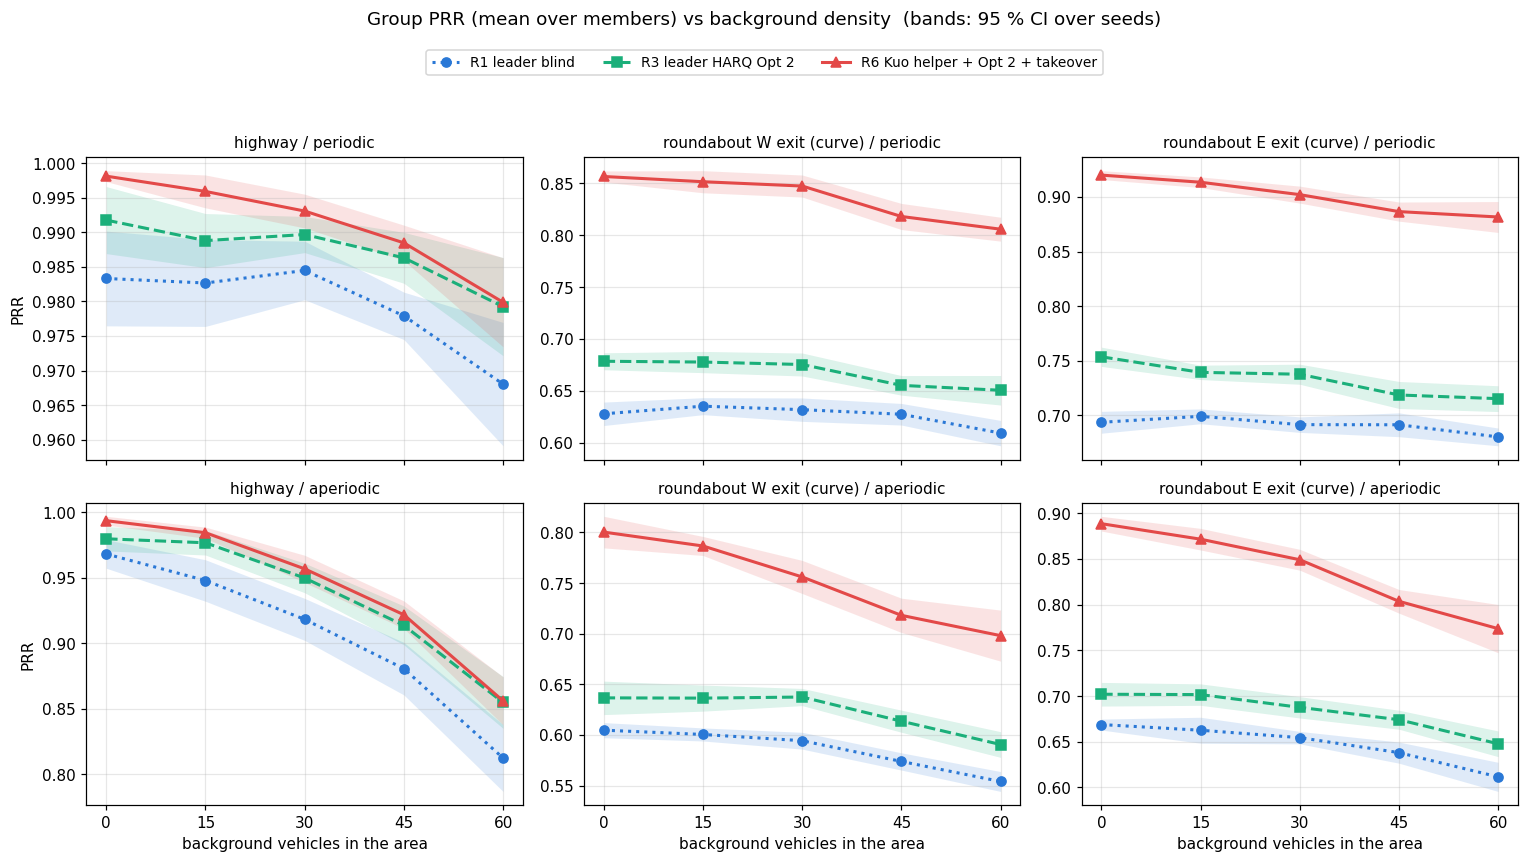

In [3]:
by_density('prr', 'Group PRR (mean over members) vs background density', 'PRR')

## 2. Worst-member PRR vs density

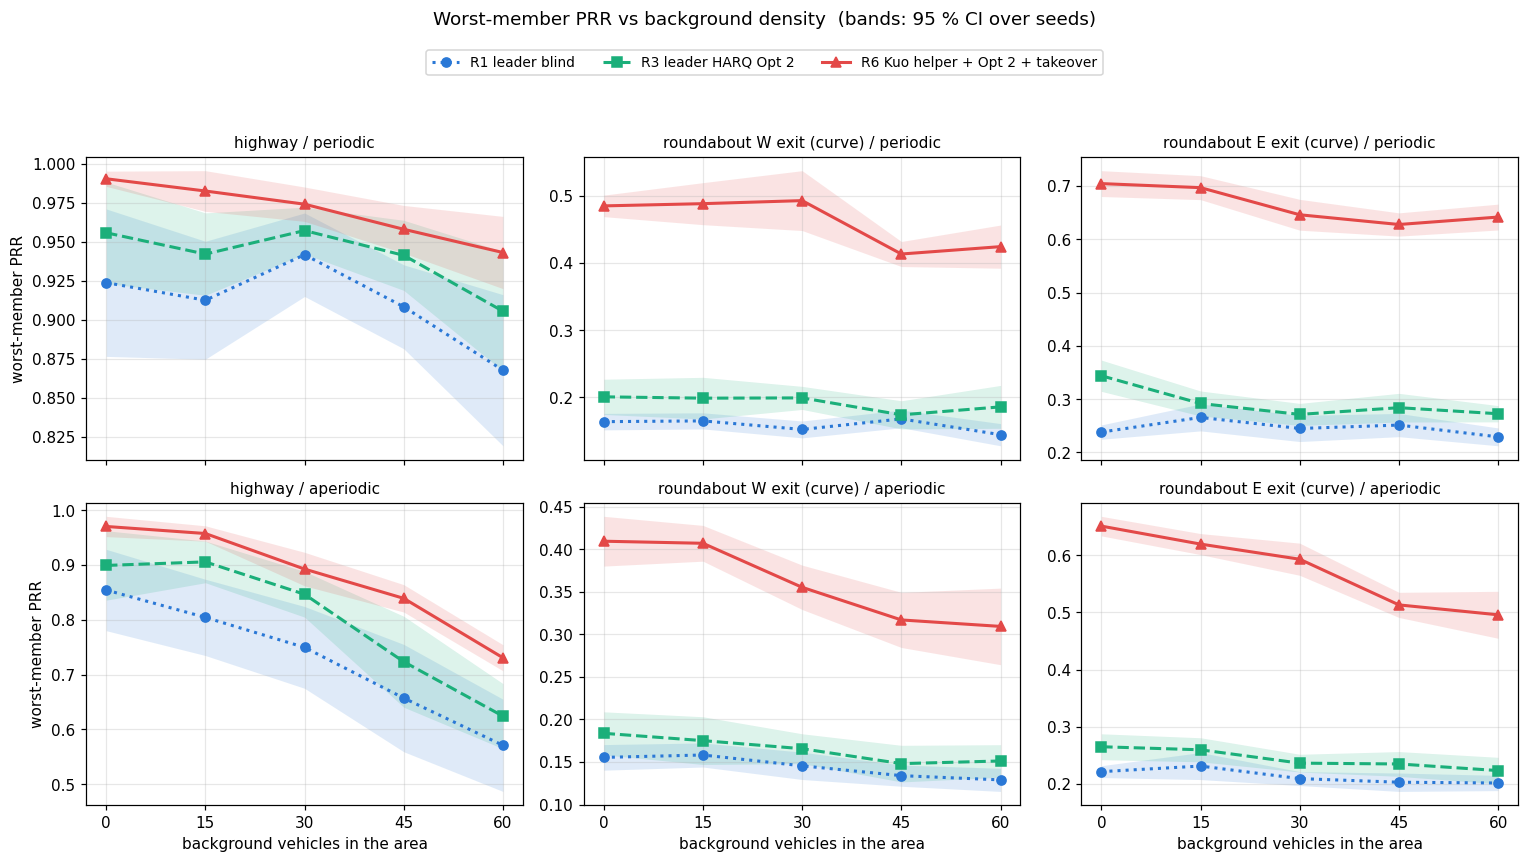

In [4]:
by_density('worst', 'Worst-member PRR vs background density', 'worst-member PRR')

## 3. Gain of R6 over R1 and R3 vs density (paired per seed)

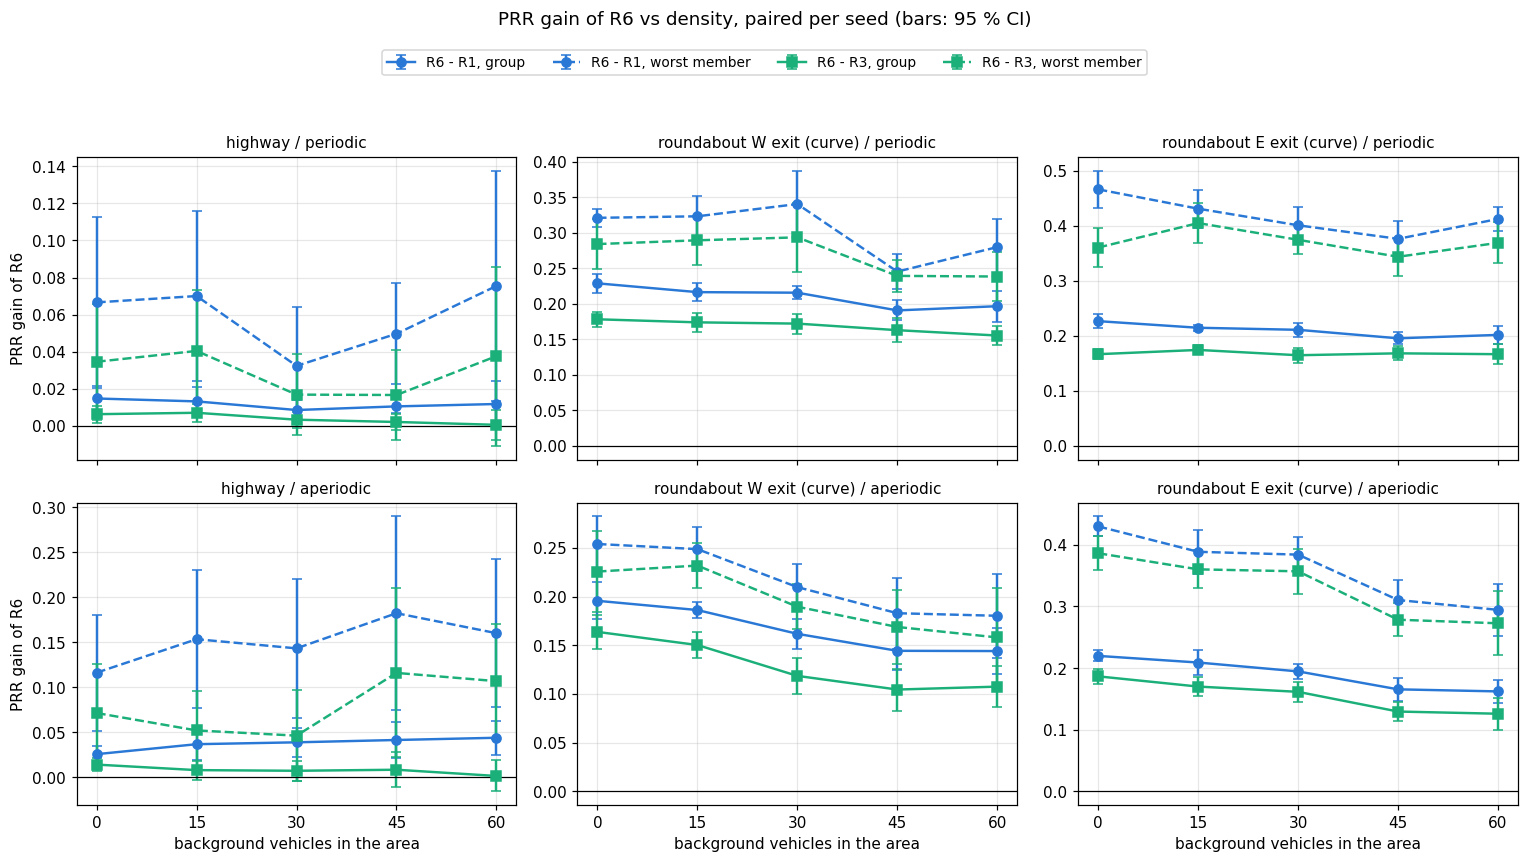

d_prr                                  \
nbg                                0               15              30   
sc   tr           ref                                                   
hwy  aperiodic1tb R1   +0.025 ± 0.009  +0.037 ± 0.017  +0.039 ± 0.016   
                  R3   +0.014 ± 0.007  +0.008 ± 0.010  +0.007 ± 0.011   
     periodic1tb  R1   +0.015 ± 0.007  +0.013 ± 0.008  +0.009 ± 0.005   
                  R3   +0.006 ± 0.005  +0.007 ± 0.005  +0.003 ± 0.004   
rbt  aperiodic1tb R1   +0.196 ± 0.019  +0.186 ± 0.008  +0.162 ± 0.015   
                  R3   +0.164 ± 0.017  +0.150 ± 0.013  +0.119 ± 0.019   
     periodic1tb  R1   +0.229 ± 0.013  +0.216 ± 0.013  +0.216 ± 0.010   
                  R3   +0.178 ± 0.011  +0.174 ± 0.013  +0.172 ± 0.014   
rbtE aperiodic1tb R1   +0.220 ± 0.009  +0.209 ± 0.020  +0.195 ± 0.012   
                  R3   +0.187 ± 0.012  +0.170 ± 0.015  +0.161 ± 0.016   
     periodic1tb  R1   +0.227 ± 0.012  +0.215 ± 0.005  +0.211 ± 0.012   
                  R3   +0.167 ± 0.009  +0.174 ± 0.008  +0.165 ± 0.013   

                                                              d_worst  \
nbg                                45              60              0    
sc   tr           ref                                                   
hwy  aperiodic1tb R1   +0.041 ± 0.020  +0.044 ± 0.019  +0.116 ± 0.065   
                  R3   +0.008 ± 0.020  +0.001 ± 0.017  +0.071 ± 0.055   
     periodic1tb  R1   +0.011 ± 0.004  +0.012 ± 0.013  +0.067 ± 0.046   
                  R3   +0.002 ± 0.005  +0.001 ± 0.008  +0.035 ± 0.031   
rbt  aperiodic1tb R1   +0.144 ± 0.020  +0.144 ± 0.024  +0.254 ± 0.028   
                  R3   +0.105 ± 0.022  +0.108 ± 0.021  +0.226 ± 0.042   
     periodic1tb  R1   +0.191 ± 0.014  +0.197 ± 0.022  +0.321 ± 0.012   
                  R3   +0.163 ± 0.017  +0.155 ± 0.014  +0.284 ± 0.035   
rbtE aperiodic1tb R1   +0.166 ± 0.019  +0.162 ± 0.019  +0.430 ± 0.016   
                  R3   +0.130 ± 0.015  +0.126 ± 0.026  +0.386 ± 0.028   
     periodic1tb  R1   +0.195 ± 0.011  +0.202 ± 0.016  +0.466 ± 0.034   
                  R3   +0.168 ± 0.013  +0.167 ± 0.018  +0.360 ± 0.036   

                                                                       \
nbg                                15              30              45   
sc   tr           ref                                                   
hwy  aperiodic1tb R1   +0.153 ± 0.077  +0.143 ± 0.077  +0.182 ± 0.108   
                  R3   +0.052 ± 0.043  +0.046 ± 0.050  +0.116 ± 0.094   
     periodic1tb  R1   +0.070 ± 0.046  +0.032 ± 0.032  +0.050 ± 0.027   
                  R3   +0.040 ± 0.033  +0.017 ± 0.022  +0.017 ± 0.024   
rbt  aperiodic1tb R1   +0.249 ± 0.023  +0.210 ± 0.024  +0.183 ± 0.037   
                  R3   +0.232 ± 0.023  +0.190 ± 0.023  +0.169 ± 0.038   
     periodic1tb  R1   +0.323 ± 0.029  +0.340 ± 0.047  +0.245 ± 0.025   
                  R3   +0.289 ± 0.034  +0.293 ± 0.049  +0.239 ± 0.023   
rbtE aperiodic1tb R1   +0.389 ± 0.036  +0.384 ± 0.029  +0.310 ± 0.032   
                  R3   +0.360 ± 0.031  +0.357 ± 0.036  +0.278 ± 0.027   
     periodic1tb  R1   +0.431 ± 0.035  +0.401 ± 0.033  +0.376 ± 0.032   
                  R3   +0.405 ± 0.036  +0.375 ± 0.026  +0.344 ± 0.035   

                                       
nbg                                60  
sc   tr           ref                  
hwy  aperiodic1tb R1   +0.160 ± 0.082  
                  R3   +0.107 ± 0.064  
     periodic1tb  R1   +0.075 ± 0.062  
                  R3   +0.038 ± 0.048  
rbt  aperiodic1tb R1   +0.180 ± 0.043  
                  R3   +0.158 ± 0.051  
     periodic1tb  R1   +0.280 ± 0.040  
                  R3   +0.238 ± 0.035  
rbtE aperiodic1tb R1   +0.294 ± 0.042  
                  R3   +0.273 ± 0.052  
     periodic1tb  R1   +0.412 ± 0.022  
                  R3   +0.369 ± 0.038

In [5]:
X = D.set_index(['sc', 'tr', 'nbg', 'seed', 'arm'])[['prr', 'worst']].unstack('arm')
G = []
for (sc, tr, nbg, seed), r in X.iterrows():
    for ref in ('R1', 'R3'):
        G.append(dict(sc=sc, tr=tr, nbg=nbg, ref=ref, d_prr=r[('prr', 'R6')] - r[('prr', ref)],
                      d_worst=r[('worst', 'R6')] - r[('worst', ref)]))
G = pd.DataFrame(G)
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True, squeeze=False)
for i, tr in enumerate(TRAF):
    for j, sc in enumerate(SCEN):
        ax = axes[i, j]
        for ref, mk in (('R1', 'o'), ('R3', 's')):
            for met, ls in (('d_prr', '-'), ('d_worst', '--')):
                g = G[(G.sc == sc) & (G.tr == tr) & (G.ref == ref)].groupby('nbg')[met].agg(['mean', ci95])
                col = STYLE[ref][0]
                ax.errorbar(g.index, g['mean'], yerr=g['ci95'], fmt=ls, marker=mk, color=col, capsize=3, lw=1.6,
                            label=f'R6 - {ref}, {"group" if met == "d_prr" else "worst member"}')
        ax.axhline(0, color='k', lw=.8)
        ax.set_title(f'{SCEN[sc]} / {TRAF[tr]}', fontsize=10); ax.grid(alpha=.3); ax.set_xticks(list(NBG.values()))
        if j == 0: ax.set_ylabel('PRR gain of R6')
        if i == 1: ax.set_xlabel('background vehicles in the area')
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc='upper center', ncol=4, fontsize=9, bbox_to_anchor=(.5, 1.0))
fig.suptitle('PRR gain of R6 vs density, paired per seed (bars: 95 % CI)', y=1.04)
fig.tight_layout(rect=(0, 0, 1, .95)); plt.show()
G.groupby(['sc', 'tr', 'ref', 'nbg'])[['d_prr', 'd_worst']].agg(lambda x: f'{x.mean():+.3f} ± {ci95(x):.3f}').unstack('nbg')

## 4. Cost: resources per packet and channel busy ratio vs density

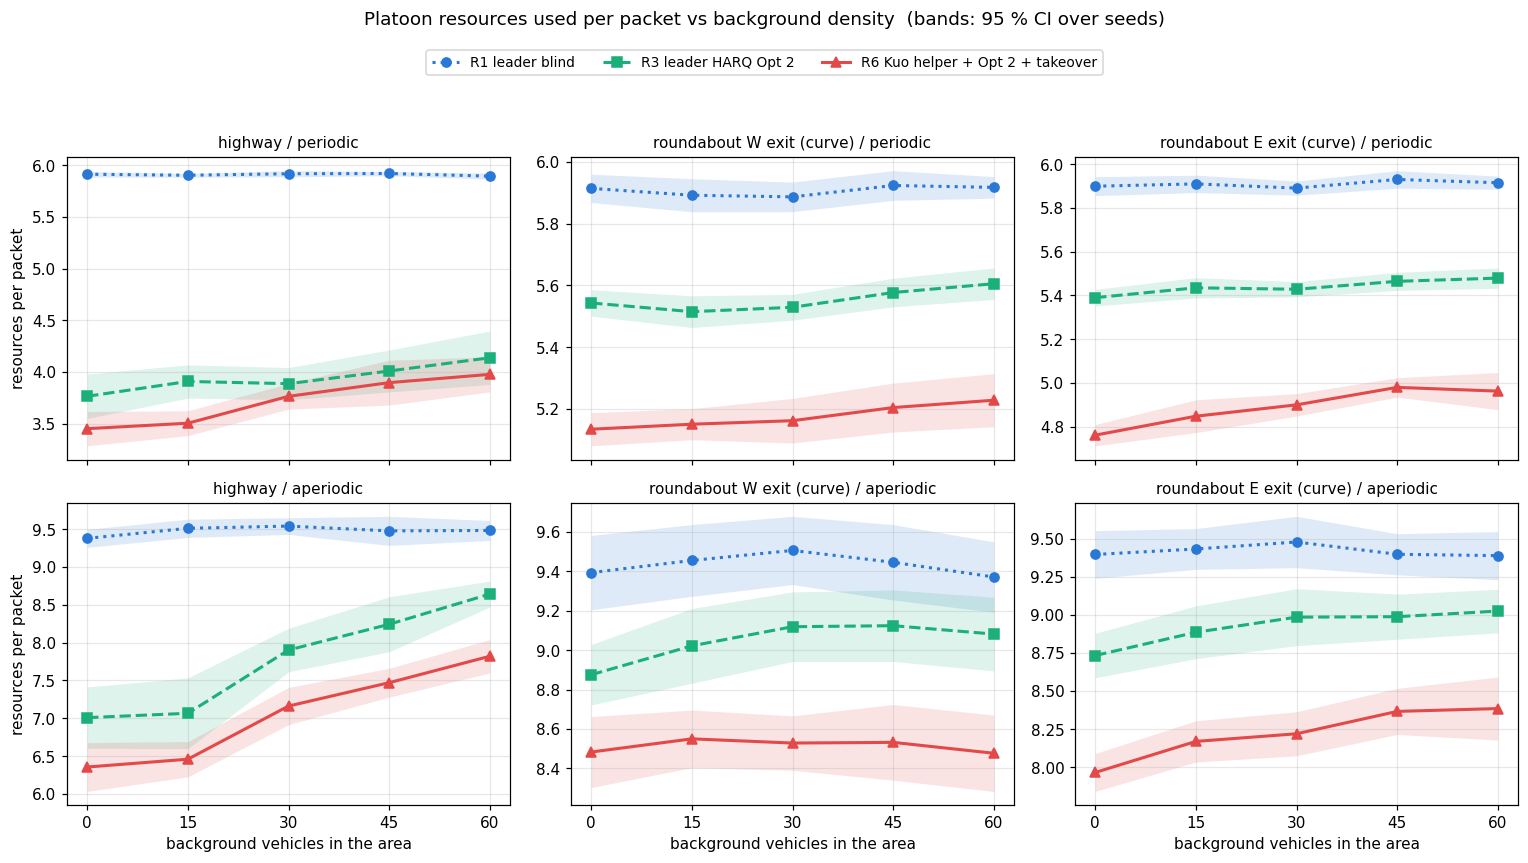

In [6]:
by_density('res', 'Platoon resources used per packet vs background density', 'resources per packet')

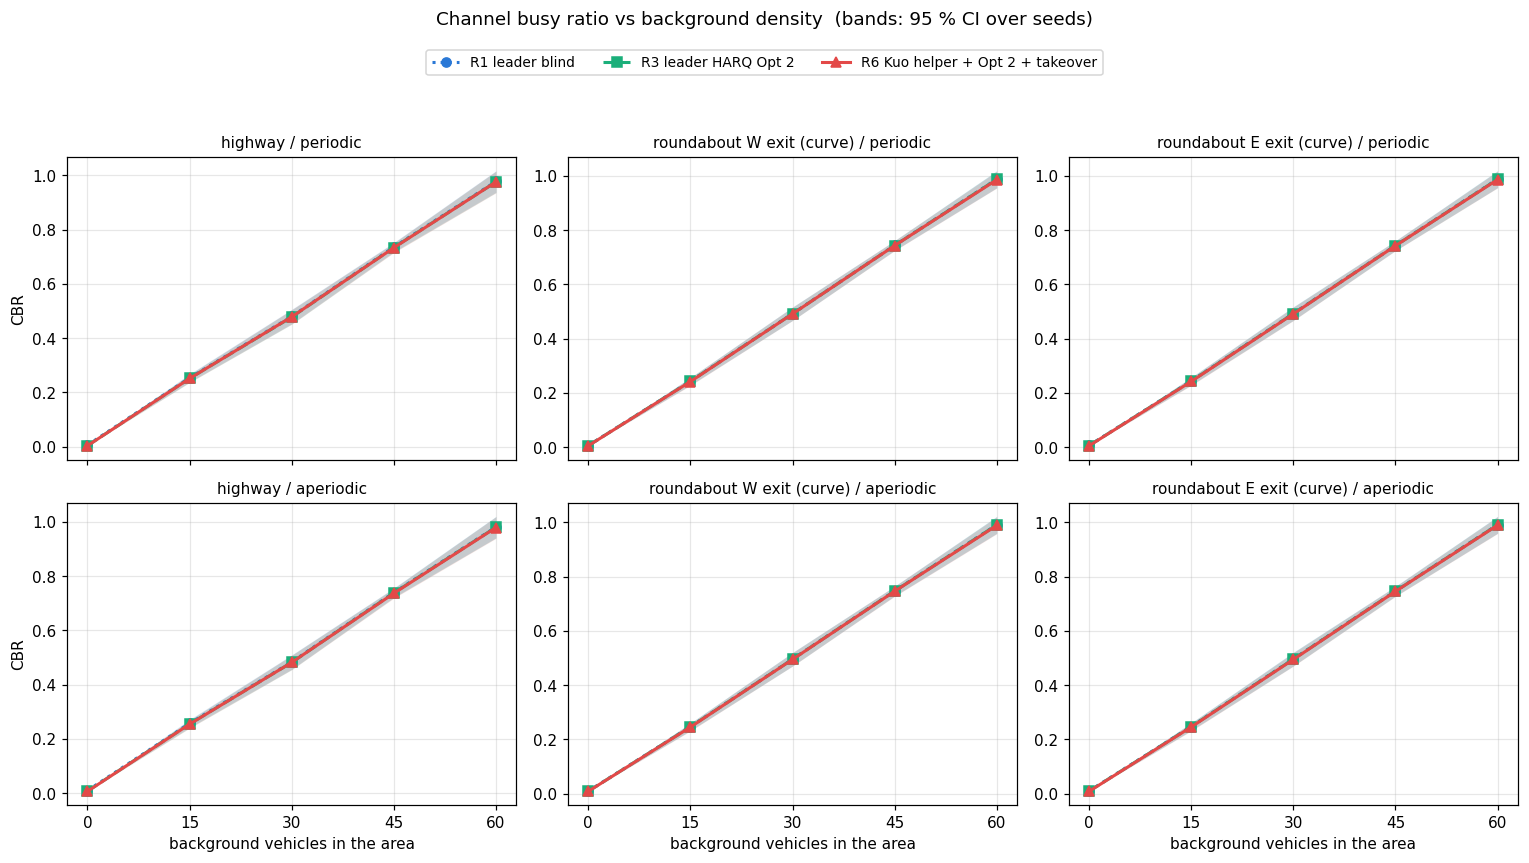

In [7]:
by_density('cbr', 'Channel busy ratio vs background density', 'CBR')

## 5. R6 takeover activity vs density
Reclaims on a helper NACK and fallback retransmissions per packet, and the share of TBs whose SCI the helper missed (what the fallback covers).

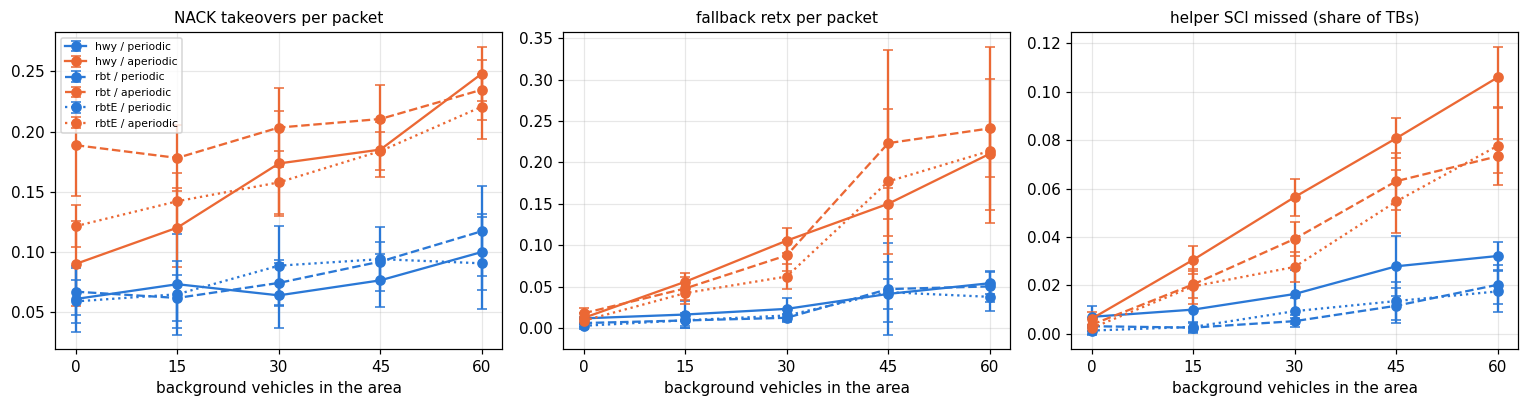

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (met, lab) in zip(axes, [('reclaim', 'NACK takeovers per packet'), ('fallback', 'fallback retx per packet'),
                                  ('sci_miss', 'helper SCI missed (share of TBs)')]):
    for sc, ls in zip(SCEN, ['-', '--', ':']):
        for tr, col in zip(TRAF, ['#2a78d6', '#eb6834']):
            g = D[(D.arm == 'R6') & (D.sc == sc) & (D.tr == tr)].groupby('nbg')[met].agg(['mean', ci95])
            ax.errorbar(g.index, g['mean'], yerr=g['ci95'], fmt=ls, marker='o', color=col, capsize=3,
                        label=f'{sc} / {TRAF[tr]}')
    ax.set_title(lab, fontsize=10); ax.grid(alpha=.3); ax.set_xticks(list(NBG.values()))
    ax.set_xlabel('background vehicles in the area')
axes[0].legend(fontsize=7)
fig.tight_layout(); plt.show()

## 6. PRR vs distance at each density
Per-seed binned PRR (35 m bins; roundabout: curve packets only), mean and 95 % CI over seeds.

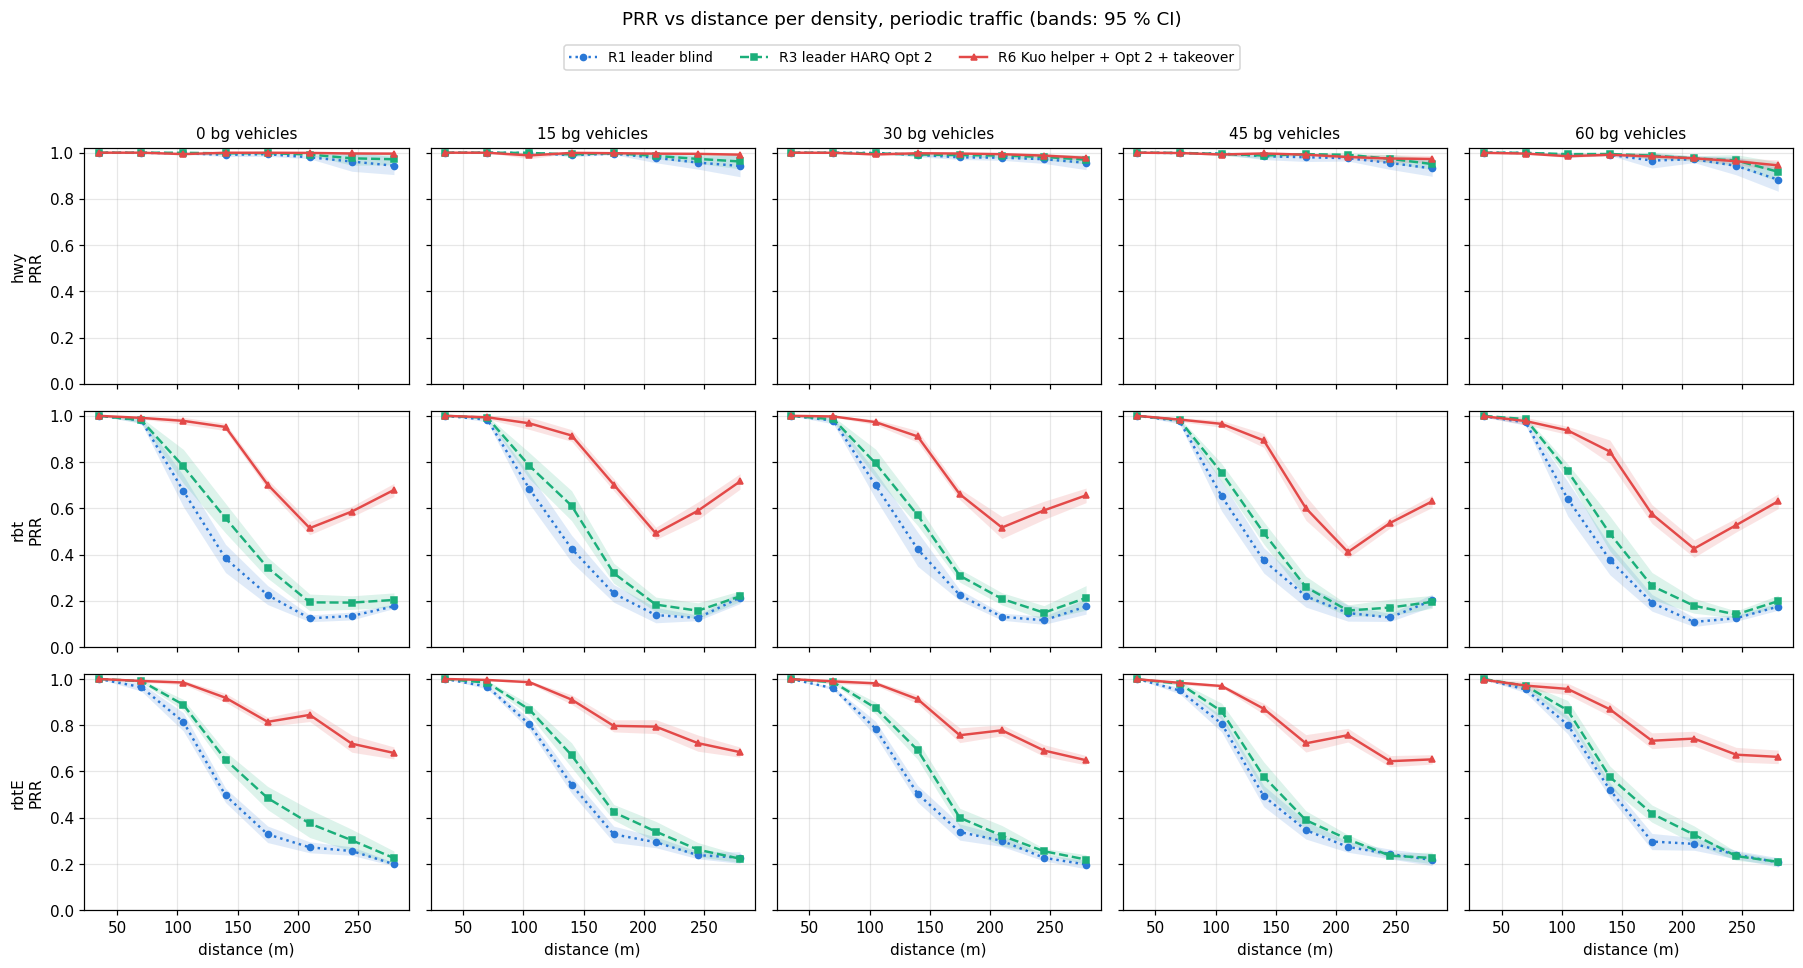

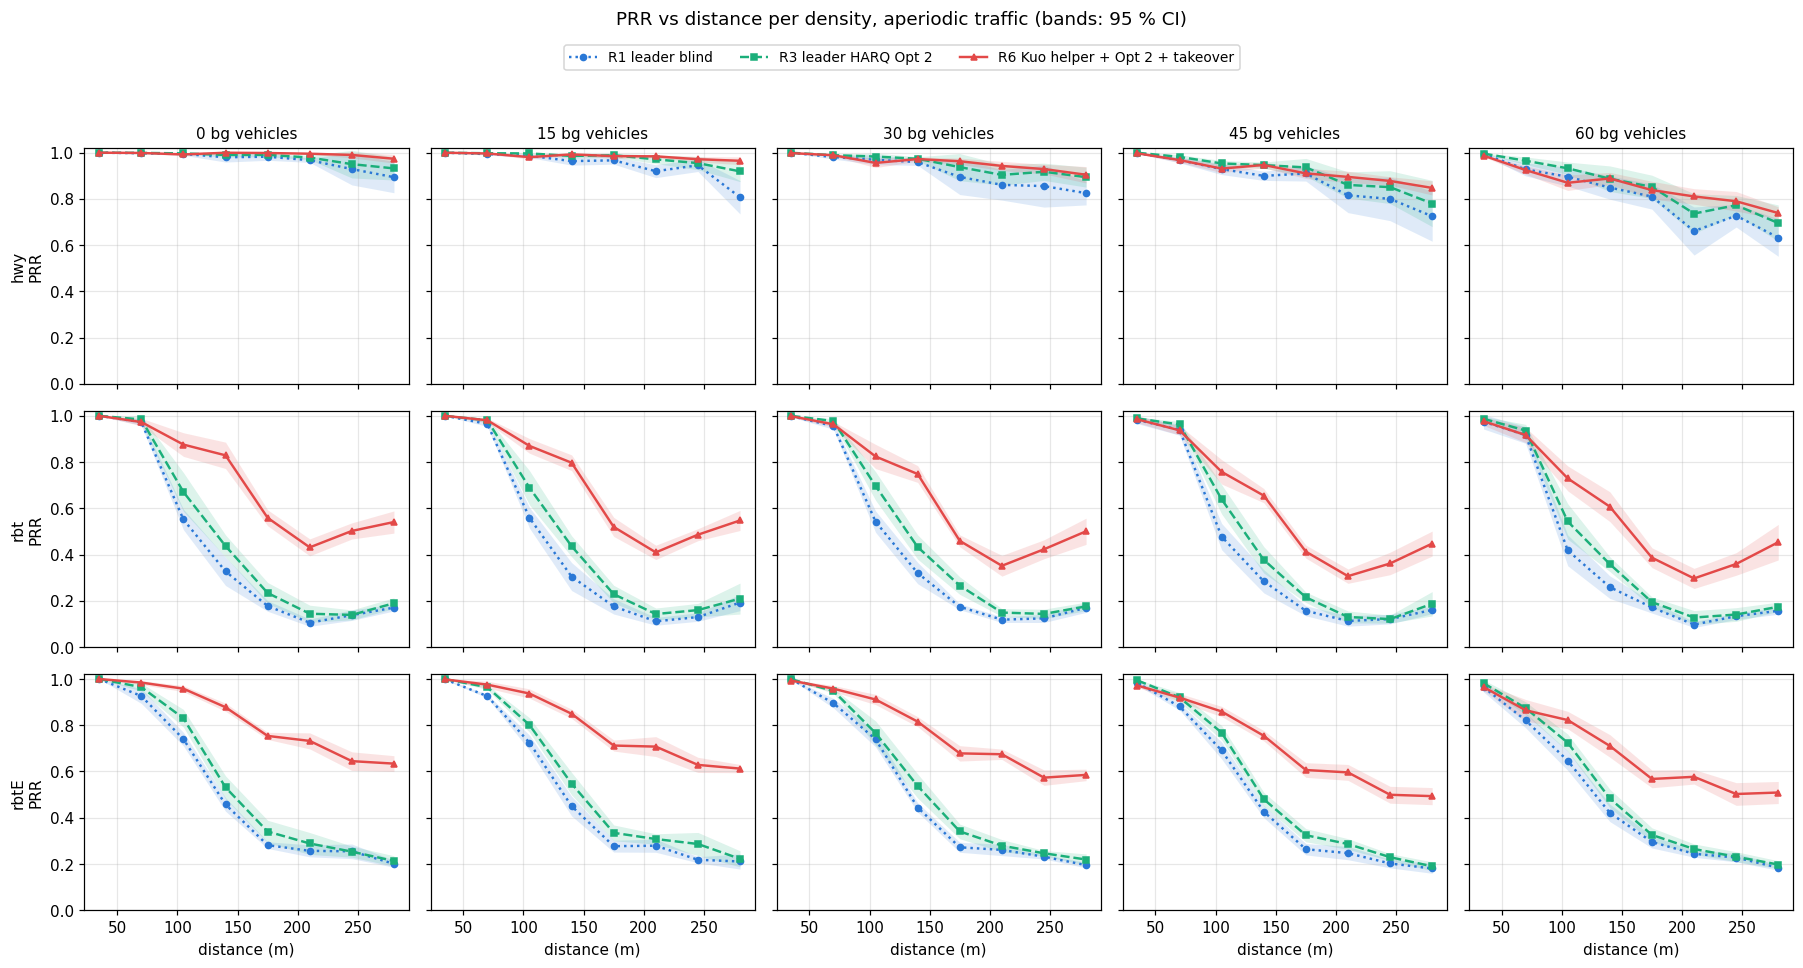

In [9]:
for tr in TRAF:
    dens = sorted(P.nbg.unique())
    fig, axes = plt.subplots(len(SCEN), len(dens), figsize=(3.3 * len(dens), 8.5), sharex=True, sharey=True, squeeze=False)
    for i, sc in enumerate(SCEN):
        for j, nb in enumerate(dens):
            ax = axes[i, j]
            for arm in ARMS:
                g = P[(P.sc == sc) & (P.tr == tr) & (P.nbg == nb) & (P.arm == arm) & (P.n >= 10)].groupby('d').prr.agg(['mean', ci95])
                col, ls, mk = STYLE[arm]
                ax.plot(g.index, g['mean'], ls, color=col, marker=mk, ms=4, lw=1.6, label=LABEL[arm])
                ax.fill_between(g.index, g['mean'] - g['ci95'], g['mean'] + g['ci95'], color=col, alpha=.15, lw=0)
            ax.set_ylim(0, 1.02); ax.grid(alpha=.3)
            if i == 0: ax.set_title(f'{nb} bg vehicles', fontsize=10)
            if j == 0: ax.set_ylabel(f'{sc}\nPRR')
            if i == len(SCEN) - 1: ax.set_xlabel('distance (m)')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=3, fontsize=9, bbox_to_anchor=(.5, 1.0))
    fig.suptitle(f'PRR vs distance per density, {TRAF[tr]} traffic (bands: 95 % CI)', y=1.03)
    fig.tight_layout(rect=(0, 0, 1, .96)); plt.show()

## 7. Table: mean ± 95 % CI

In [10]:
T = D.groupby(['sc', 'tr', 'arm', 'nbg'])[['prr', 'worst', 'res']].agg(lambda x: f'{x.mean():.3f} ± {ci95(x):.3f}')
display(T['prr'].unstack('nbg')); display(T['worst'].unstack('nbg')); T['res'].unstack('nbg')

nbg                               0              15             30  \
sc   tr           arm                                                
hwy  aperiodic1tb R1   0.968 ± 0.011  0.948 ± 0.016  0.918 ± 0.016   
                  R3   0.980 ± 0.009  0.977 ± 0.009  0.950 ± 0.011   
                  R6   0.994 ± 0.003  0.984 ± 0.004  0.957 ± 0.010   
     periodic1tb  R1   0.983 ± 0.007  0.983 ± 0.006  0.984 ± 0.004   
                  R3   0.992 ± 0.005  0.989 ± 0.004  0.990 ± 0.003   
                  R6   0.998 ± 0.001  0.996 ± 0.002  0.993 ± 0.002   
rbt  aperiodic1tb R1   0.605 ± 0.007  0.601 ± 0.006  0.594 ± 0.008   
                  R3   0.637 ± 0.017  0.636 ± 0.013  0.637 ± 0.008   
                  R6   0.800 ± 0.016  0.787 ± 0.009  0.756 ± 0.016   
     periodic1tb  R1   0.628 ± 0.011  0.635 ± 0.008  0.632 ± 0.011   
                  R3   0.678 ± 0.008  0.678 ± 0.010  0.675 ± 0.011   
                  R6   0.857 ± 0.005  0.852 ± 0.011  0.847 ± 0.011   
rbtE aperiodic1tb R1   0.669 ± 0.006  0.663 ± 0.014  0.654 ± 0.007   
                  R3   0.702 ± 0.013  0.702 ± 0.012  0.688 ± 0.012   
                  R6   0.889 ± 0.008  0.872 ± 0.012  0.849 ± 0.011   
     periodic1tb  R1   0.693 ± 0.010  0.699 ± 0.007  0.691 ± 0.007   
                  R3   0.754 ± 0.009  0.739 ± 0.007  0.738 ± 0.009   
                  R6   0.920 ± 0.004  0.914 ± 0.005  0.902 ± 0.008   

nbg                               45             60  
sc   tr           arm                                
hwy  aperiodic1tb R1   0.881 ± 0.020  0.812 ± 0.026  
                  R3   0.914 ± 0.015  0.855 ± 0.020  
                  R6   0.922 ± 0.011  0.856 ± 0.018  
     periodic1tb  R1   0.978 ± 0.003  0.968 ± 0.009  
                  R3   0.986 ± 0.004  0.979 ± 0.007  
                  R6   0.988 ± 0.003  0.980 ± 0.006  
rbt  aperiodic1tb R1   0.574 ± 0.009  0.554 ± 0.010  
                  R3   0.614 ± 0.011  0.591 ± 0.013  
                  R6   0.718 ± 0.017  0.698 ± 0.025  
     periodic1tb  R1   0.627 ± 0.010  0.609 ± 0.012  
                  R3   0.655 ± 0.009  0.651 ± 0.014  
                  R6   0.818 ± 0.013  0.806 ± 0.012  
rbtE aperiodic1tb R1   0.638 ± 0.012  0.612 ± 0.016  
                  R3   0.674 ± 0.010  0.648 ± 0.014  
                  R6   0.804 ± 0.013  0.774 ± 0.026  
     periodic1tb  R1   0.691 ± 0.011  0.680 ± 0.008  
                  R3   0.718 ± 0.012  0.715 ± 0.012  
                  R6   0.887 ± 0.009  0.882 ± 0.014

nbg                               0              15             30  \
sc   tr           arm                                                
hwy  aperiodic1tb R1   0.854 ± 0.074  0.804 ± 0.070  0.750 ± 0.075   
                  R3   0.899 ± 0.063  0.906 ± 0.038  0.846 ± 0.042   
                  R6   0.970 ± 0.019  0.957 ± 0.014  0.892 ± 0.031   
     periodic1tb  R1   0.924 ± 0.047  0.912 ± 0.038  0.942 ± 0.027   
                  R3   0.956 ± 0.032  0.942 ± 0.026  0.957 ± 0.015   
                  R6   0.990 ± 0.005  0.982 ± 0.013  0.974 ± 0.011   
rbt  aperiodic1tb R1   0.155 ± 0.015  0.158 ± 0.014  0.145 ± 0.016   
                  R3   0.184 ± 0.025  0.175 ± 0.028  0.166 ± 0.018   
                  R6   0.409 ± 0.029  0.407 ± 0.021  0.355 ± 0.026   
     periodic1tb  R1   0.164 ± 0.012  0.165 ± 0.012  0.152 ± 0.013   
                  R3   0.201 ± 0.026  0.199 ± 0.031  0.199 ± 0.017   
                  R6   0.485 ± 0.016  0.488 ± 0.031  0.492 ± 0.045   
rbtE aperiodic1tb R1   0.221 ± 0.010  0.231 ± 0.024  0.209 ± 0.012   
                  R3   0.265 ± 0.023  0.260 ± 0.021  0.236 ± 0.016   
                  R6   0.651 ± 0.017  0.620 ± 0.018  0.593 ± 0.028   
     periodic1tb  R1   0.238 ± 0.013  0.266 ± 0.025  0.245 ± 0.025   
                  R3   0.344 ± 0.029  0.292 ± 0.023  0.271 ± 0.021   
                  R6   0.704 ± 0.024  0.697 ± 0.022  0.646 ± 0.029   

nbg                               45             60  
sc   tr           arm                                
hwy  aperiodic1tb R1   0.657 ± 0.098  0.571 ± 0.084  
                  R3   0.723 ± 0.083  0.624 ± 0.059  
                  R6   0.839 ± 0.025  0.731 ± 0.024  
     periodic1tb  R1   0.908 ± 0.027  0.868 ± 0.048  
                  R3   0.941 ± 0.022  0.905 ± 0.038  
                  R6   0.958 ± 0.015  0.943 ± 0.023  
rbt  aperiodic1tb R1   0.134 ± 0.012  0.129 ± 0.014  
                  R3   0.148 ± 0.021  0.151 ± 0.019  
                  R6   0.317 ± 0.032  0.309 ± 0.045  
     periodic1tb  R1   0.168 ± 0.013  0.144 ± 0.016  
                  R3   0.174 ± 0.021  0.186 ± 0.032  
                  R6   0.413 ± 0.019  0.424 ± 0.032  
rbtE aperiodic1tb R1   0.203 ± 0.016  0.201 ± 0.013  
                  R3   0.235 ± 0.022  0.223 ± 0.023  
                  R6   0.513 ± 0.022  0.496 ± 0.041  
     periodic1tb  R1   0.251 ± 0.022  0.229 ± 0.017  
                  R3   0.284 ± 0.027  0.273 ± 0.015  
                  R6   0.628 ± 0.022  0.642 ± 0.024

nbg                               0              15             30  \
sc   tr           arm                                                
hwy  aperiodic1tb R1   9.379 ± 0.119  9.511 ± 0.121  9.541 ± 0.110   
                  R3   7.007 ± 0.405  7.065 ± 0.468  7.902 ± 0.288   
                  R6   6.354 ± 0.323  6.458 ± 0.234  7.161 ± 0.246   
     periodic1tb  R1   5.913 ± 0.027  5.903 ± 0.018  5.918 ± 0.030   
                  R3   3.764 ± 0.215  3.908 ± 0.161  3.886 ± 0.156   
                  R6   3.451 ± 0.166  3.503 ± 0.120  3.764 ± 0.124   
rbt  aperiodic1tb R1   9.394 ± 0.189  9.455 ± 0.182  9.506 ± 0.173   
                  R3   8.875 ± 0.153  9.022 ± 0.190  9.119 ± 0.176   
                  R6   8.483 ± 0.180  8.550 ± 0.146  8.529 ± 0.138   
     periodic1tb  R1   5.914 ± 0.046  5.891 ± 0.053  5.886 ± 0.048   
                  R3   5.543 ± 0.043  5.515 ± 0.051  5.529 ± 0.042   
                  R6   5.135 ± 0.054  5.151 ± 0.050  5.162 ± 0.072   
rbtE aperiodic1tb R1   9.396 ± 0.156  9.432 ± 0.134  9.478 ± 0.169   
                  R3   8.733 ± 0.146  8.885 ± 0.173  8.985 ± 0.187   
                  R6   7.965 ± 0.124  8.169 ± 0.135  8.219 ± 0.144   
     periodic1tb  R1   5.899 ± 0.043  5.910 ± 0.040  5.890 ± 0.033   
                  R3   5.389 ± 0.038  5.434 ± 0.047  5.428 ± 0.035   
                  R6   4.760 ± 0.049  4.847 ± 0.075  4.899 ± 0.051   

nbg                               45             60  
sc   tr           arm                                
hwy  aperiodic1tb R1   9.477 ± 0.193  9.483 ± 0.132  
                  R3   8.242 ± 0.363  8.642 ± 0.172  
                  R6   7.470 ± 0.190  7.820 ± 0.221  
     periodic1tb  R1   5.920 ± 0.021  5.895 ± 0.029  
                  R3   4.009 ± 0.203  4.137 ± 0.258  
                  R6   3.896 ± 0.217  3.976 ± 0.169  
rbt  aperiodic1tb R1   9.446 ± 0.191  9.371 ± 0.178  
                  R3   9.124 ± 0.182  9.082 ± 0.187  
                  R6   8.532 ± 0.192  8.477 ± 0.194  
     periodic1tb  R1   5.923 ± 0.048  5.917 ± 0.035  
                  R3   5.577 ± 0.046  5.605 ± 0.051  
                  R6   5.205 ± 0.079  5.228 ± 0.086  
rbtE aperiodic1tb R1   9.397 ± 0.135  9.389 ± 0.158  
                  R3   8.988 ± 0.148  9.025 ± 0.143  
                  R6   8.366 ± 0.151  8.385 ± 0.207  
     periodic1tb  R1   5.930 ± 0.040  5.915 ± 0.030  
                  R3   5.464 ± 0.041  5.479 ± 0.046  
                  R6   4.979 ± 0.045  4.962 ± 0.085